TEAM 13 ASSIGNMENT


IOANNIDIS GEORGIOS   Student ID: 10833   

PAPADOPOULOS CHARALAMPOS PANAGIOTIS Student ID: 10898 

PART A

Class 0 mean:
x1    29.209038
x2    16.849889
dtype: float64

Class 1 mean:
x1    40.197669
x2    34.281091
dtype: float64

Class 2 mean:
x1    27.552325
x2    34.793180
dtype: float64

Class 0 sigma:
           x1         x2
x1  46.985913  22.905323
x2  22.905323  48.631336

Class 1 sigma:
           x1         x2
x1   9.423905  11.489718
x2  11.489718  20.108056

Class 2 sigma:
           x1         x2
x1  13.968744  11.774336
x2  11.774336  25.288482



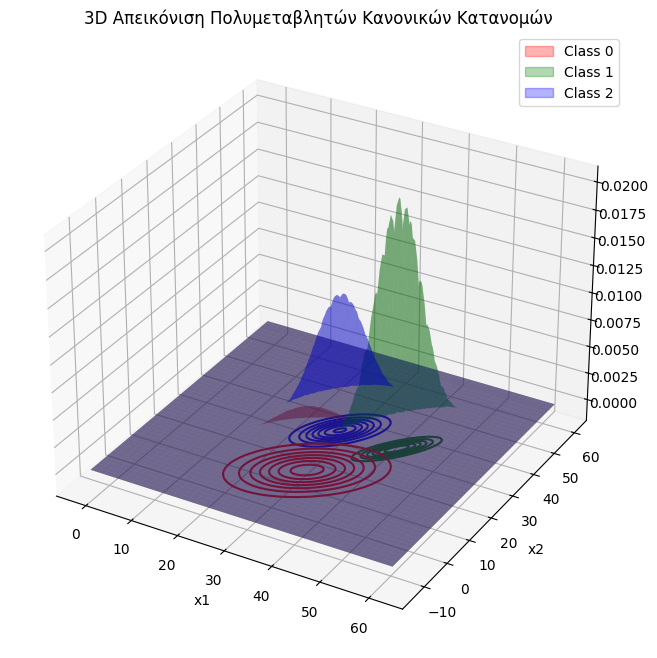

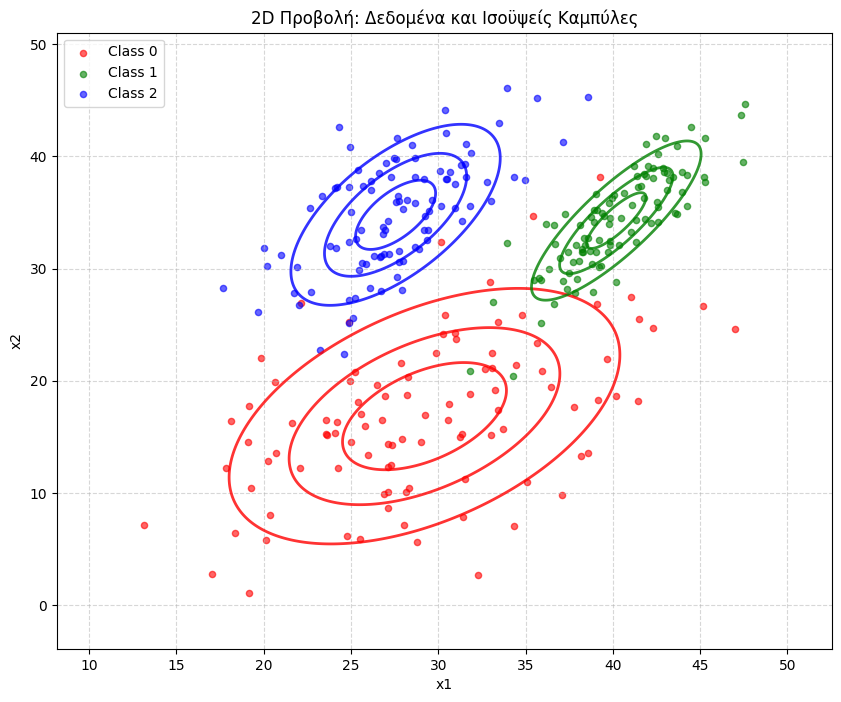

In [1]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

# Load the file and set the column names (x1, x2, Class)
data=pd.read_csv("C:/Users/User/Desktop/Assignment_2025-2026/dataset1.csv", names=['x1', 'x2', 'Class'])         

#Split the data into 3 separate DataFrames, one per class
class0_df = data[data['Class']==0][['x1','x2']]
class1_df = data[data['Class']==1][['x1','x2']]
class2_df = data[data['Class']==2][['x1','x2']]
class_data = [class0_df, class1_df, class2_df]


#Compute the covariance matrix of each class
means = []

for i, class_n in enumerate(class_data):
    # Formula: 1/N * Σ(x)
    mean = (1/100) * class_n.sum(axis=0)
    means.append(mean)
    print(f"Class {i} mean:\n{mean}\n")



sigmas = []

for i, class_n in enumerate(class_data):
    diff = class_n - means[i]
    # Formula: 1/N * (X-μ)^T * (X-μ)
    sigma = (1/100) * (diff.T @ diff)
    sigmas.append(sigma)
    print(f"Class {i} sigma:\n{sigma}\n")

from scipy.stats import multivariate_normal
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

#Show it in a 3D plot
# Set the limits and the grid to draw the curves
padding = 15
x_min, x_max = data['x1'].min() - padding, data['x1'].max() + padding
y_min, y_max = data['x2'].min() - padding, data['x2'].max() + padding
h = 0.5

x, y = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
pos = np.dstack((x, y))

# Set up the 3D plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

colors = ['red', 'green', 'blue']
labels = ['Class 0', 'Class 1', 'Class 2']

# For each class, build the distribution and add it to the plot
for i in range(3):
    rv = multivariate_normal(means[i], sigmas[i])
    z = rv.pdf(pos)
    # Surface plot: the bell of the distribution
    ax.plot_surface(x, y, z, color=colors[i], alpha=0.3)
    # Contour plot: the contour lines on the floor of the plot
    ax.contour(x, y, z, zdir='z', offset=-0.002, colors=colors[i], linewidths=1.5)

# Add legend and labels
legend_patches = [mpatches.Patch(color=colors[i], label=labels[i], alpha=0.3) for i in range(3)]
ax.legend(handles=legend_patches, loc='upper right')

ax.set_title('3D View of the Multivariate Normal Distributions')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('Probability Density P(x)', labelpad=20)
ax.set_zlim(bottom=-0.002)

plt.show()

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

#2D view of the data and the contour lines
# Set the limits and the grid to draw the curves
padding = 5
x_min, x_max = data['x1'].min() - padding, data['x1'].max() + padding
y_min, y_max = data['x2'].min() - padding, data['x2'].max() + padding
h = 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
pos = np.dstack((xx, yy))


plt.figure(figsize=(10, 8))
colors = ['red', 'green', 'blue']
labels = ['Class 0', 'Class 1', 'Class 2']

# Plot the data
for i, df in enumerate(class_data):
    plt.scatter(df['x1'], df['x2'], c=colors[i], label=f'{labels[i]}', alpha=0.6, s=20)

for i in range(3):
    rv = multivariate_normal(means[i], sigmas[i])
    Z = rv.pdf(pos)
    # Draw 3 contour levels for each class
    plt.contour(xx, yy, Z, levels=3, colors=colors[i], linewidths=2, alpha=0.8)

plt.title('2D View: Data and Contour Lines')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()


PART B

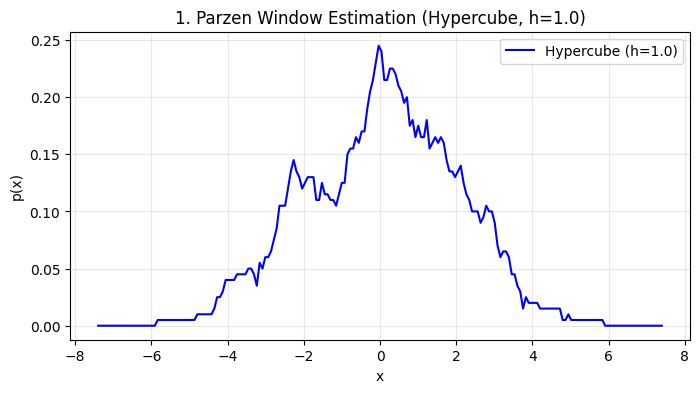

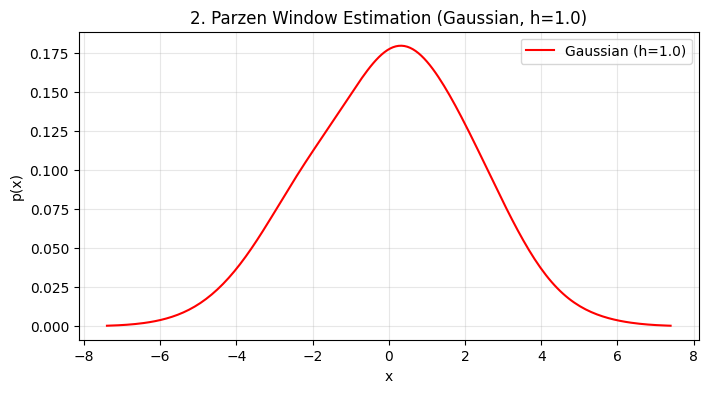

Optimizing h...
gauss mse: 0.001116661708502482
hyper mse: 0.0017936193407798718
Best h (Hypercube): 2.8
Best h (Gaussian): 0.8


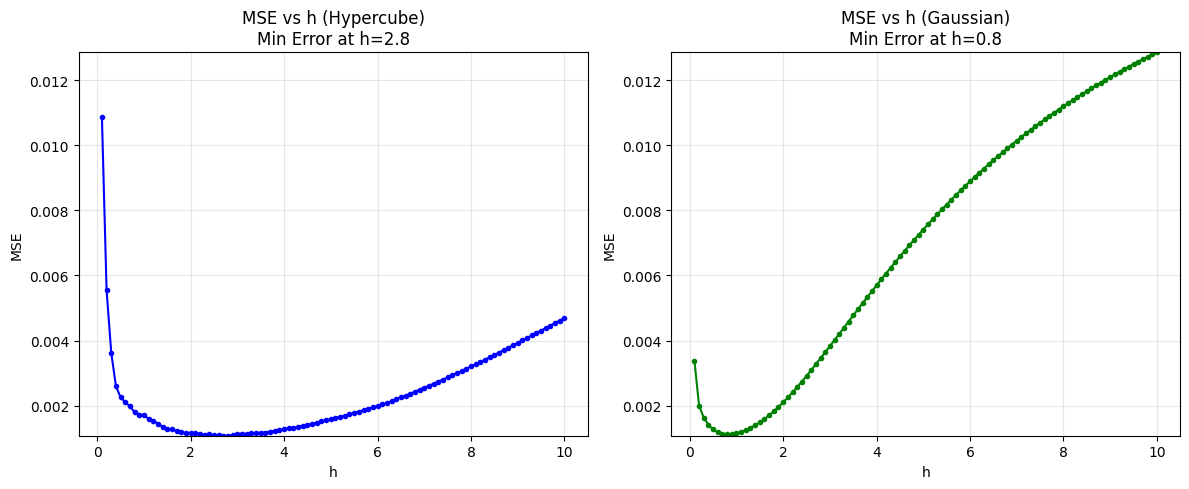

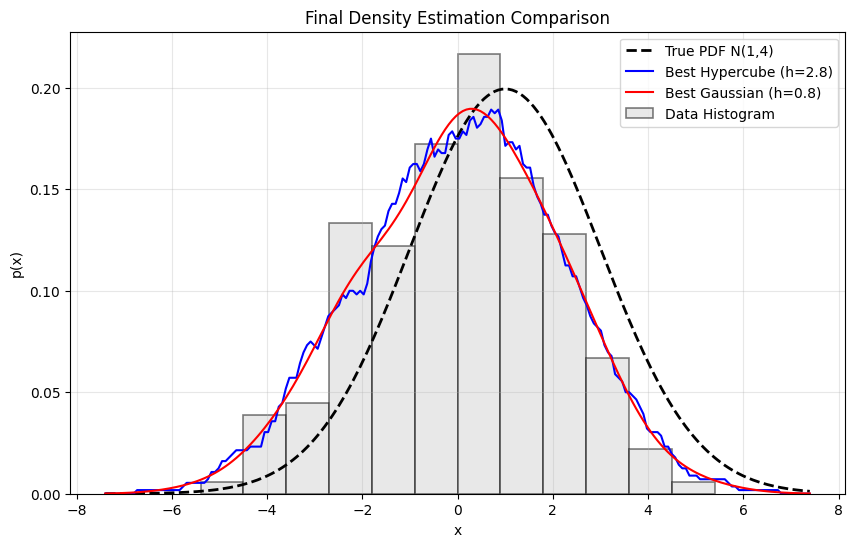

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Load the data 
path = r"C:/Users/User/Desktop/Assignment_2025-2026/dataset2.csv"
dataset2 = pd.read_csv(path, header=None)
data = dataset2.values.flatten() # Turn it into a 1D array
N = len(data)

#Define the functions (kernels & estimator)

#Hypercube kernel function 
def hypercube_kernel(u):
    #
    if abs(u) <= 0.5:
        return 1
    else:
        return 0
#Gaussian kernel function
def gaussian_kernel(u):
    return (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * u**2)

#General Parzen estimation function 
#target_points: the points we want to plot or check
#train_data: the data used for the estimate
#kernel_function: the kernel function to use

def parzen_estimator(target_points, train_data, h, kernel_function):
    
    results = []
    n_train = len(train_data)
    
    for x in target_points:
        # Add up the contribution of every data point
        k_sum = sum(kernel_function((x - x_i) / h) for x_i in train_data)
        
        # Apply the formula: 1 / (N * h) * Sum
        p_hat = (1 / (n_train * h)) * k_sum
        results.append(p_hat)
        
    return np.array(results)

#First plot (with h=1)
h_init = 1.0
# Axis for the plots (a bit wider than our data)
x_axis = np.linspace(data.min()-2, data.max()+2, 200)

#Compute both estimates with the initial h
y_hyper_init = parzen_estimator(x_axis, data, h_init, hypercube_kernel)
y_gauss_init = parzen_estimator(x_axis, data, h_init, gaussian_kernel)

# Plot 1: Parzen Hypercube
plt.figure(figsize=(8, 4))
plt.plot(x_axis, y_hyper_init, color='blue', label=f'Hypercube (h={h_init})')
plt.title(f'1. Parzen Window Estimation (Hypercube, h={h_init})')
plt.xlabel('x')
plt.ylabel('p(x)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot 2: Parzen Gaussian
plt.figure(figsize=(8, 4))
plt.plot(x_axis, y_gauss_init, color='red', label=f'Gaussian (h={h_init})')
plt.title(f'2. Parzen Window Estimation (Gaussian, h={h_init})')
plt.xlabel('x')
plt.ylabel('p(x)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#Tuning h (finding the minimum error)

# We know the data come from a normal distribution N(1, 4).
# This is our reference.
mu = 1
sigma = 2 #σ=sqrt(4)
def true_pdf(x):
    return (1 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-0.5 * ((x - mu) / sigma)**2)

# True probabilities at the data points
true_probs_data = true_pdf(data)

# Try many values of h (0.1 to 10, step 0.1) to find the one with the smallest error
h_values = np.arange(0.1, 10.1, 0.1)
errors_hyper = []
errors_gauss = []

print("Optimizing h...")

for h in h_values:
    #Compute the model's estimate
    est_hyper = parzen_estimator(data, data, h, hypercube_kernel)
    #Mean squared error (MSE) against the true distribution
    mse_hyper = np.mean((est_hyper - true_probs_data)**2)
    mse_hyper = np.mean((est_hyper - true_probs_data)**2)
    errors_hyper.append(mse_hyper)
    
    # Same for the Gaussian kernel
    est_gauss = parzen_estimator(data, data, h, gaussian_kernel)
    mse_gauss = np.mean((est_gauss - true_probs_data)**2)
    errors_gauss.append(mse_gauss)

# Find the best h with argmin
best_h_hyper = h_values[np.argmin(errors_hyper)]
best_h_gauss = h_values[np.argmin(errors_gauss)]


est_hyper_best = parzen_estimator(data, data, best_h_gauss, hypercube_kernel)
est_gauss_best = parzen_estimator(data, data, best_h_gauss, gaussian_kernel)

mse_hyper = np.mean((est_hyper_best- true_probs_data)**2)
mse_gauss = np.mean((est_gauss_best  - true_probs_data)**2)
print("gauss mse:", mse_gauss)
print("hyper mse:", mse_hyper)

print(f"Best h (Hypercube): {best_h_hyper:.1f}")
print(f"Best h (Gaussian): {best_h_gauss:.1f}")

# Plot 3: how the error changes as h changes
plt.figure(figsize=(12, 5))

# Same limits on the y axis
y_min = min(min(errors_hyper), min(errors_gauss))
y_max = max(max(errors_hyper), max(errors_gauss))

plt.subplot(1, 2, 1)
plt.plot(h_values, errors_hyper, 'b-o', markersize=3)
plt.title(f'MSE vs h (Hypercube)\nMin Error at h={best_h_hyper:.1f}')
plt.xlabel('h')
plt.ylabel('MSE')
plt.ylim(y_min, y_max)   #same scale
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(h_values, errors_gauss, 'g-o', markersize=3)
plt.title(f'MSE vs h (Gaussian)\nMin Error at h={best_h_gauss:.1f}')
plt.xlabel('h')
plt.ylabel('MSE')
plt.ylim(y_min, y_max)   
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


#=Final comparison plot 

# Compute the best curves over the whole x axis
final_hyper = parzen_estimator(x_axis, data, best_h_hyper, hypercube_kernel)
final_gauss = parzen_estimator(x_axis, data, best_h_gauss, gaussian_kernel)
final_true = true_pdf(x_axis)

plt.figure(figsize=(10, 6))
plt.plot(x_axis, final_true, 'k--', linewidth=2, label='True PDF N(1,4)')
plt.plot(x_axis, final_hyper, 'b-', label=f'Best Hypercube (h={best_h_hyper:.1f})')
plt.plot(x_axis, final_gauss, 'r-', label=f'Best Gaussian (h={best_h_gauss:.1f})')
plt.hist(data, bins='auto', density=True, alpha=0.5, color='lightgray', edgecolor='black', linewidth=1.2, label='Data Histogram')
plt.title('Final Density Estimation Comparison')
plt.xlabel('x')
plt.ylabel('p(x)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

PART C


The best value of k is: 11
With maximum accuracy: 74.00%


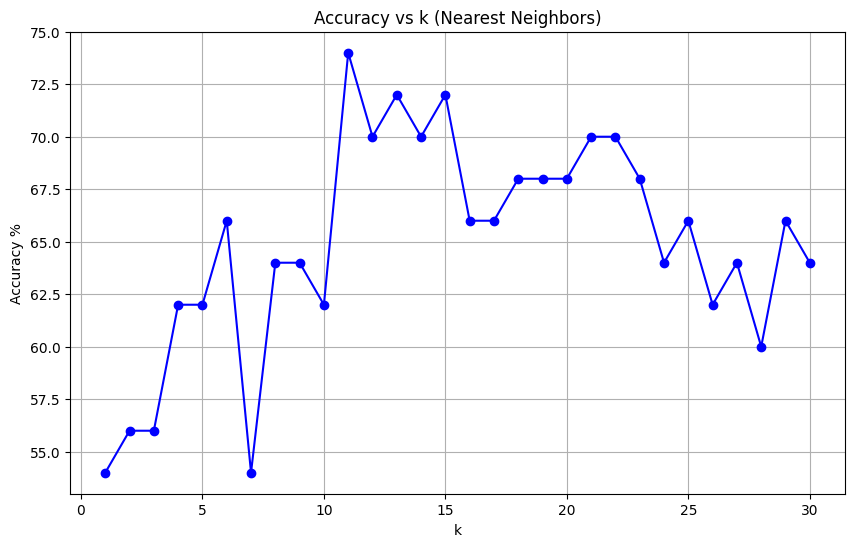

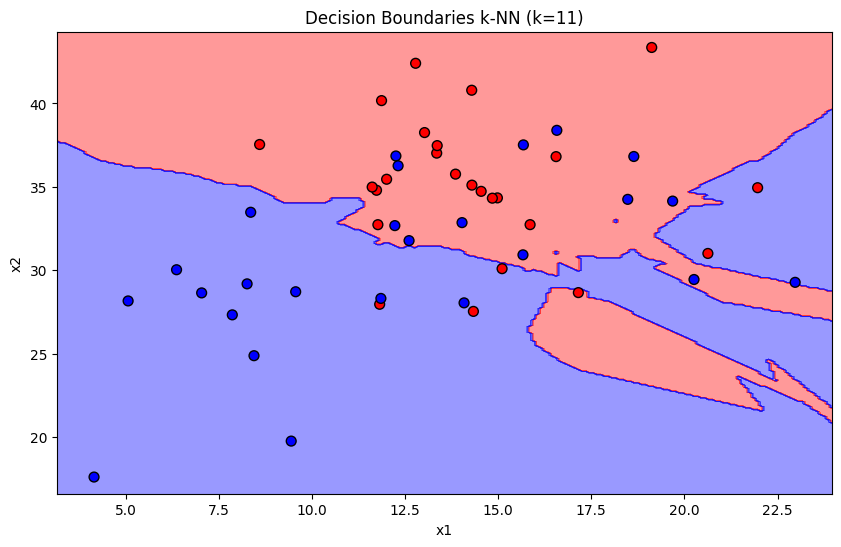

In [17]:
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
dataset3 = pd.read_csv(r"C:\Users\User\Desktop\Assignment_2025-2026\dataset3.csv", names=['x1', 'x2', 'Class'])
testset = pd.read_csv(r"C:\Users\User\Desktop\Assignment_2025-2026\testset.csv", names=['x1', 'x2', 'Class'])
# 2. Convert to numpy arrays 
trainData = dataset3.values
testData = testset.values

def eucl(x, trainData):
    # Take all of trainData EXCEPT the last column, which holds the labels
    features_only = trainData[:, :-1]
    
    # Subtract the point x from the whole x train
    squared_diff = (features_only - x) ** 2
    # Sum of squared differences for each row
    sum_squared = np.sum(squared_diff, axis=1)
    distances = np.sqrt(sum_squared)
    
    return distances

def neighbors(x, trainData, k):
    # Distances with the eucl function I wrote earlier
    dists = eucl(x, trainData)
    # Sort and get the position indices
    sorted_indices = np.argsort(dists)
    # Keep the first k
    k_indices = sorted_indices[:k]
    # Return the top k points from trainData
    return trainData[k_indices]

def predict(testData, trainData, k):
    probabilities = []
    
    # Take the features of testData (without the label)
    X_test = testData[:, :-1]
    
    for x in X_test:
        # 1. Find the k nearest neighbours (whole row: x1, x2, label)
        nearest_rows = neighbors(x, trainData, k)
        
        # 2. Keep ONLY the last column (the labels)
        k_labels = nearest_rows[:, -1]
        
        # 3. Count how many neighbours are class 0 and how many class 1
        count_0 = np.sum(k_labels == 0)
        count_1 = np.sum(k_labels == 1)
        
        # 4. Compute the percentages
        prob_0 = count_0 / k
        prob_1 = count_1 / k
        if not np.isclose(prob_0 + prob_1, 1.0):
            print("Error: the probabilities do not sum to 1!")
        #add them to the list
        probabilities.append([prob_0, prob_1])
    #return the probabilities
    return np.array(probabilities)

k_values = range(1, 31)
accuracies = []

# initialise variables to find the best k
best_k = -1
max_accuracy = 0.0

for k in k_values:
    correct_predictions = 0
    total_points = len(testData)
    
    for row in testData:
        # Separate x from the label 
        x_test = row[:-1]      
        true_label = row[-1]   
        
        # 1. Find the neighbours by calling the function
        my_neighbors = neighbors(x_test, trainData, k)
        
        # 2. Get their labels
        neighbor_labels = my_neighbors[:, -1]
        
        # If the sum of the k nearest labels is > k/2, the majority is 1
        if np.sum(neighbor_labels) > k / 2:
            prediction = 1.0
        else:
            prediction = 0.0
            
        # Check if we got it right
        if prediction == true_label:
            correct_predictions += 1
            
    # Accuracy for this k
    current_accuracy = correct_predictions / total_points
    accuracies.append(current_accuracy)
    
    # Update the best k
    if current_accuracy > max_accuracy:
        max_accuracy = current_accuracy
        best_k = k

print(f"The best value of k is: {best_k}")
print(f"With maximum accuracy: {max_accuracy * 100:.2f}%")

# Plot
plt.figure(figsize=(10, 6))
plt.plot(k_values, np.array(accuracies) * 100, marker='o', linestyle='-', color='b')
plt.title('Accuracy vs k (Nearest Neighbors)')
plt.xlabel('k')
plt.ylabel('Accuracy %')
plt.grid(True)
plt.show()

#Decision boundaries

# Map limits
x_min, x_max = trainData[:, 0].min() - 1, trainData[:, 0].max() + 1
y_min, y_max = trainData[:, 1].min() - 1, trainData[:, 1].max() + 1

# Build the grid 
h = 0.1 #Window width
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),#go from min to max with step h, then meshgrid turns it into a square grid
                     np.arange(y_min, y_max, h))

# Predictions for the grid
Z = []
for point in np.c_[xx.ravel(), yy.ravel()]:#goes row by row, flattens to 1D, and point=x,y
    nearest_neighbors = neighbors(point, trainData, best_k)
    labels = nearest_neighbors[:, -1]
    # fills the list: 1 if the sum > k/2, else 0
    Z.append(1 if np.sum(labels) > best_k/2 else 0)
#convert to np with the shape of xx
Z = np.array(Z).reshape(xx.shape)

# Plot 
plt.figure(figsize=(10, 6))
my_colors = ListedColormap(['red', 'blue'])

#call contourf to draw the decision regions
plt.contourf(xx, yy, Z, alpha=0.4, cmap=my_colors)
plt.scatter(trainData[:, 0], trainData[:, 1], c=trainData[:, -1], edgecolor='k', cmap=my_colors, s=50)

plt.title(f'Decision Boundaries k-NN (k={best_k})')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()